In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!pip install numpy matplotlib tensorflow
!pip install git+https://github.com/matterport/Mask_RCNN.git


  Cloning https://github.com/matterport/Mask_RCNN.git to /tmp/pip-req-build-sh2wg2dx
  Running command git clone --filter=blob:none --quiet https://github.com/matterport/Mask_RCNN.git /tmp/pip-req-build-sh2wg2dx
  Resolved https://github.com/matterport/Mask_RCNN.git to commit 3deaec5d902d16e1daf56b62d5971d428dc920bc
  Preparing metadata (setup.py) ... done
  Created wheel for mask-rcnn: filename=mask_rcnn-2.1-py3-none-any.whl size=56922 sha256=7959b313f3f9c04ca4533f16eccb701534bac5933eb9cf6f2d3b26039ad57ed0
  Stored in directory: /tmp/pip-ephem-wheel-cache-9ib5ri76/wheels/63/8e/bf/ef4901e305146aa3a21fbbaac877c3a204180eca9a71c8e291
Successfully built mask-rcnn


In [3]:
!pip install git+https://github.com/akTwelve/Mask_RCNN.git


  Cloning https://github.com/akTwelve/Mask_RCNN.git to /tmp/pip-req-build-fjbwfqst
  Running command git clone --filter=blob:none --quiet https://github.com/akTwelve/Mask_RCNN.git /tmp/pip-req-build-fjbwfqst
  Resolved https://github.com/akTwelve/Mask_RCNN.git to commit d9f01dcd83b1e90e5ea0b4b6d5ba753770e114ac
  Preparing metadata (setup.py) ... done


In [4]:
!pip install opencv-python-headless  # Görüntü işleme için


In [5]:
from mrcnn import utils


In [6]:
class CancerDataset(utils.Dataset):

    def load_cancer(self, dataset_dir, subset):
        self.add_class("cancer", 1, "cancer")
        assert subset in ["train", "val"]
        dataset_dir = os.path.join(dataset_dir, subset)
        image_ids = next(os.walk(dataset_dir))[2]

        for image_id in image_ids:
            self.add_image(
                "cancer",
                image_id=image_id,
                path=os.path.join(dataset_dir, image_id),
                mask_path=os.path.join('/content/masks', image_id.replace('.jpg', '_mask.jpg'))  # Maske dosyasının yolunu düzeltin
            )

    def load_mask(self, image_id):
        info = self.image_info[image_id]
        mask_path = info['mask_path']
        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)  # Maskeyi gri tonlamalı olarak okuyun
        if mask is None:
            raise Exception("Mask not found for image_id:", image_id)
        mask = np.expand_dims(mask, axis=-1)  # Maskeyi (H, W, 1) boyutuna getirin
        return mask, np.ones([mask.shape[-1]], dtype=np.int32)


In [5]:
from mrcnn.config import Config


ModuleNotFoundError: No module named 'mrcnn'

In [12]:
class CancerConfig(Config):
    NAME = "cancer_detection"
    IMAGES_PER_GPU = 2
    NUM_CLASSES = 1 + 1  # Arka plan + kanser
    STEPS_PER_EPOCH = 100
    DETECTION_MIN_CONFIDENCE = 0.9


In [9]:
!pip install git+https://github.com/akTwelve/Mask_RCNN.git


  Cloning https://github.com/akTwelve/Mask_RCNN.git to /tmp/pip-req-build-5x46vka8
  Running command git clone --filter=blob:none --quiet https://github.com/akTwelve/Mask_RCNN.git /tmp/pip-req-build-5x46vka8
  Resolved https://github.com/akTwelve/Mask_RCNN.git to commit d9f01dcd83b1e90e5ea0b4b6d5ba753770e114ac
  Preparing metadata (setup.py) ... done


In [14]:
!pip install git+https://github.com/akTwelve/Mask_RCNN.git


  Cloning https://github.com/akTwelve/Mask_RCNN.git to /tmp/pip-req-build-jbyq0_is
  Running command git clone --filter=blob:none --quiet https://github.com/akTwelve/Mask_RCNN.git /tmp/pip-req-build-jbyq0_is
  Resolved https://github.com/akTwelve/Mask_RCNN.git to commit d9f01dcd83b1e90e5ea0b4b6d5ba753770e114ac
  Preparing metadata (setup.py) ... done


In [18]:
# Eski:

# Yeni:
import tensorflow.keras.engine as KE


ModuleNotFoundError: No module named 'tensorflow.keras.engine'

In [16]:
from mrcnn import model as modellib


ModuleNotFoundError: No module named 'keras.engine'

In [15]:
config = CancerConfig()
model = modellib.MaskRCNN(mode="training", config=config, model_dir='/content/logs')

# Eğitim veri setini yükleyin ve hazırlayın
dataset_train = CancerDataset()
dataset_train.load_cancer('/content/orjinals', 'train')
dataset_train.prepare()

# Doğrulama veri setini yükleyin ve hazırlayın
dataset_val = CancerDataset()
dataset_val.load_cancer('/content/orjinals', 'val')
dataset_val.prepare()

# Modeli eğitin
model.train(dataset_train, dataset_val,
            learning_rate=config.LEARNING_RATE,
            epochs=30,
            layers='heads')


NameError: name 'modellib' is not defined

#DETECTRON2

In [2]:
# PyTorch ve torchvision kurulumu
!pip install torch torchvision

# Detectron2 kurulumu
!python -m pip install 'git+https://github.com/facebookresearch/detectron2.git'


  Cloning https://github.com/facebookresearch/detectron2.git to /tmp/pip-req-build-jxp_lfv8
  Running command git clone --filter=blob:none --quiet https://github.com/facebookresearch/detectron2.git /tmp/pip-req-build-jxp_lfv8
  Resolved https://github.com/facebookresearch/detectron2.git to commit 3ff5dd1cff4417af07097064813c9f28d7461d3c
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 3.1 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 6.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.5/154.5 kB 7.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 10.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 117.0/117.0 kB 8.4 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for detectron2: filename=detectron2-0.6-cp310-cp310-linux_x86_64.whl size=6120418 sha256=6fa63098dbe354b262edb5b8c68e91

In [3]:
import detectron2
from detectron2.utils.logger import setup_logger
setup_logger()

# Detectron2'nin diğer modülleri
from detectron2 import model_zoo
from detectron2.engine import DefaultTrainer
from detectron2.config import get_cfg
from detectron2.utils.visualizer import Visualizer
from detectron2.data import MetadataCatalog, DatasetCatalog


In [12]:
def get_dataset_dicts(json_file):
    with open(json_file) as f:
        data = json.load(f)  # JSON dosyasını oku ve veriyi bir değişkene ata
        images_anns = data["images"]

    dataset_dicts = []
    for image_ann in images_anns:
        record = {
            "file_name": os.path.join("/content/drive/MyDrive/originals", image_ann["file_name"]),
            "image_id": image_ann["id"],
            "height": image_ann["height"],
            "width": image_ann["width"],
            "annotations": []
        }

        for annotation in data["annotations"]:
            if annotation["image_id"] == image_ann["id"]:
                obj = {
                    "bbox": annotation["bbox"],
                    "bbox_mode": BoxMode.XYWH_ABS,
                    "category_id": annotation.get("category_id", 0),  # Varsayılan olarak 0
                    "segmentation": annotation.get("segmentation", []),
                }
                record["annotations"].append(obj)

        dataset_dicts.append(record)

    return dataset_dicts


In [5]:
from detectron2.data import DatasetCatalog, MetadataCatalog

def register_dataset():
    DatasetCatalog.register("my_dataset", lambda: get_dataset_dicts("/content/drive/MyDrive/annotations.json"))
    MetadataCatalog.get("my_dataset").set(thing_classes=["Cancer"])

register_dataset()


In [13]:
import os

cfg = get_cfg()
cfg.merge_from_file(model_zoo.get_config_file("COCO-InstanceSegmentation/mask_rcnn_R_50_FPN_3x.yaml"))
cfg.DATASETS.TRAIN = ("my_dataset",)
cfg.DATASETS.TEST = ()
cfg.DATALOADER.NUM_WORKERS = 2
cfg.MODEL.WEIGHTS = model_zoo.get_checkpoint_url("COCO-InstanceSegmentation/mask_rcnn_R_50_FPN_3x.yaml")
cfg.SOLVER.IMS_PER_BATCH = 2
cfg.SOLVER.BASE_LR = 0.00025
cfg.SOLVER.MAX_ITER = 3000
cfg.MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE = 128
cfg.MODEL.ROI_HEADS.NUM_CLASSES = 1

os.makedirs(cfg.OUTPUT_DIR, exist_ok=True)
trainer = DefaultTrainer(cfg)
trainer.resume_or_load(resume=False)
trainer.train()

[02/19 18:13:46 d2.engine.defaults]: Model:
GeneralizedRCNN(
  (backbone): FPN(
    (fpn_lateral2): Conv2d(256, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output2): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (fpn_lateral3): Conv2d(512, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output3): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (fpn_lateral4): Conv2d(1024, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output4): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (fpn_lateral5): Conv2d(2048, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output5): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (top_block): LastLevelMaxPool()
    (bottom_up): ResNet(
      (stem): BasicStem(
        (conv1): Conv2d(
          3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False
          (norm): FrozenBatchNorm2d(num_features=64, eps=1e-05)
        )
      )
      (res

model_final_f10217.pkl: 178MB [00:01, 110MB/s]                           
roi_heads.box_predictor.bbox_pred.{bias, weight}
roi_heads.box_predictor.cls_score.{bias, weight}
roi_heads.mask_head.predictor.{bias, weight}


[02/19 18:13:49 d2.engine.train_loop]: Starting training from iteration 0


/usr/local/lib/python3.10/dist-packages/torch/functional.py:504: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at ../aten/src/ATen/native/TensorShape.cpp:3526.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


[02/19 18:14:01 d2.utils.events]:  eta: 0:17:27  iter: 19  total_loss: 2.613  loss_cls: 0.7458  loss_box_reg: 0.234  loss_mask: 0.6907  loss_rpn_cls: 0.6853  loss_rpn_loc: 0.1284    time: 0.3667  last_time: 0.4520  data_time: 0.0752  last_data_time: 0.1011   lr: 4.9953e-06  max_mem: 2459M
[02/19 18:14:12 d2.utils.events]:  eta: 0:18:09  iter: 39  total_loss: 2.454  loss_cls: 0.6362  loss_box_reg: 0.2169  loss_mask: 0.6877  loss_rpn_cls: 0.5638  loss_rpn_loc: 0.1472    time: 0.3754  last_time: 0.3934  data_time: 0.0525  last_data_time: 0.0280   lr: 9.9902e-06  max_mem: 2459M
[02/19 18:14:19 d2.utils.events]:  eta: 0:17:49  iter: 59  total_loss: 1.769  loss_cls: 0.5051  loss_box_reg: 0.4126  loss_mask: 0.6798  loss_rpn_cls: 0.1614  loss_rpn_loc: 0.09772    time: 0.3758  last_time: 0.3469  data_time: 0.0496  last_data_time: 0.0145   lr: 1.4985e-05  max_mem: 2459M
[02/19 18:14:27 d2.utils.events]:  eta: 0:17:51  iter: 79  total_loss: 1.752  loss_cls: 0.4026  loss_box_reg: 0.4326  loss_mask

[02/19 18:58:57 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/drive/MyDrive/output/model_final.pth ...


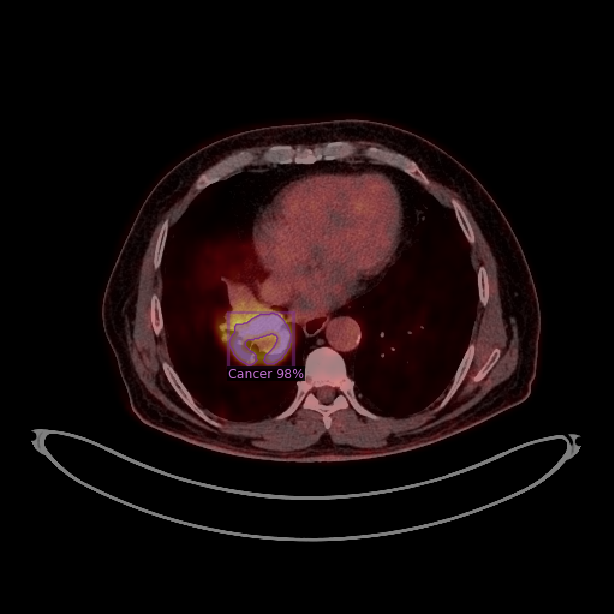

-1

In [21]:
from detectron2.engine import DefaultPredictor
from detectron2.utils.visualizer import Visualizer
from detectron2.data import MetadataCatalog
from google.colab.patches import cv2_imshow
import cv2


# Model ağırlıklarını yükle
cfg.MODEL.WEIGHTS = os.path.join(cfg.OUTPUT_DIR, "/content/drive/MyDrive/output/model_final.pth")  # Eğitimden sonra kaydedilen model ağırlıklarının yolu
cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = 0.7   # Tahminler için eşik değeri
predictor = DefaultPredictor(cfg)

# Tahmin yapılacak görüntüyü yükle
img = cv2.imread("/content/drive/MyDrive/originals/(120-160)0009.png")  # Tahmin yapmak istediğiniz görüntünün yolu

# Tahminleri gerçekleştir
outputs = predictor(img)

# Tahminleri görselleştir
v = Visualizer(img[:, :, ::-1], MetadataCatalog.get(cfg.DATASETS.TRAIN[0]), scale=1.2)
v = v.draw_instance_predictions(outputs["instances"].to("cpu"))
cv2_imshow(v.get_image()[:, :, ::-1])
cv2.waitKey(0)


In [28]:
from detectron2.evaluation import COCOEvaluator, inference_on_dataset
from detectron2.data import build_detection_test_loader

# Değerlendiriciyi oluştur
evaluator = COCOEvaluator("my_dataset", cfg, False, output_dir="/content/output_2")

# Veri yükleyiciyi oluştur
val_loader = build_detection_test_loader(cfg, "my_dataset")

# Değerlendirmeyi yap
inference_on_dataset(trainer.model, val_loader, evaluator)


WARNING [02/19 19:27:50 d2.evaluation.coco_evaluation]: COCO Evaluator instantiated using config, this is deprecated behavior. Please pass in explicit arguments instead.
[02/19 19:27:52 d2.data.dataset_mapper]: [DatasetMapper] Augmentations used in inference: [ResizeShortestEdge(short_edge_length=(800, 800), max_size=1333, sample_style='choice')]
[02/19 19:27:52 d2.data.common]: Serializing the dataset using: <class 'detectron2.data.common._TorchSerializedList'>
[02/19 19:27:52 d2.data.common]: Serializing 2983 elements to byte tensors and concatenating them all ...
[02/19 19:27:52 d2.data.common]: Serialized dataset takes 3.57 MiB
[02/19 19:27:52 d2.evaluation.evaluator]: Start inference on 2983 batches
[02/19 19:27:58 d2.evaluation.evaluator]: Inference done 11/2983. Dataloading: 0.7898 s/iter. Inference: 0.0943 s/iter. Eval: 0.0033 s/iter. Total: 0.8875 s/iter. ETA=0:43:57
[02/19 19:28:03 d2.evaluation.evaluator]: Inference done 64/2983. Dataloading: 0.0823 s/iter. Inference: 0.0859

FileNotFoundError: Caught FileNotFoundError in DataLoader worker process 0.
Original Traceback (most recent call last):
  File "/usr/local/lib/python3.10/dist-packages/torch/utils/data/_utils/worker.py", line 308, in _worker_loop
    data = fetcher.fetch(index)
  File "/usr/local/lib/python3.10/dist-packages/torch/utils/data/_utils/fetch.py", line 51, in fetch
    data = [self.dataset[idx] for idx in possibly_batched_index]
  File "/usr/local/lib/python3.10/dist-packages/torch/utils/data/_utils/fetch.py", line 51, in <listcomp>
    data = [self.dataset[idx] for idx in possibly_batched_index]
  File "/usr/local/lib/python3.10/dist-packages/detectron2/data/common.py", line 125, in __getitem__
    data = self._map_func(self._dataset[cur_idx])
  File "/usr/local/lib/python3.10/dist-packages/detectron2/utils/serialize.py", line 26, in __call__
    return self._obj(*args, **kwargs)
  File "/usr/local/lib/python3.10/dist-packages/detectron2/data/dataset_mapper.py", line 154, in __call__
    i

-----------------------------------------------------------------------

In [ ]:
!pip install git+https://github.com/akTwelve/Mask_RCNN.git


  Cloning https://github.com/akTwelve/Mask_RCNN.git to /tmp/pip-req-build-qgy__t9j
  Running command git clone --filter=blob:none --quiet https://github.com/akTwelve/Mask_RCNN.git /tmp/pip-req-build-qgy__t9j
  Resolved https://github.com/akTwelve/Mask_RCNN.git to commit d9f01dcd83b1e90e5ea0b4b6d5ba753770e114ac
  Preparing metadata (setup.py) ... done


In [ ]:
!pip install opencv-python-headless  # Görüntü işleme için


In [ ]:
!pip install --upgrade tensorflow

In [ ]:
!pip install keras

In [ ]:
import keras
print(keras.__version__)

2.15.0


In [ ]:
import os
import numpy as np
import tensorflow as tf
from mrcnn.config import Config
from mrcnn import model as modellib
from mrcnn import utils
import cv2  # OpenCV kütüphanesi


ModuleNotFoundError: No module named 'keras.engine'

In [ ]:
import os
import numpy as np
from mrcnn.config import Config
from mrcnn import model as  utils
import cv2

# Veri yükleyici sınıfınız
class CancerDataset(utils.Dataset):

    def load_cancer(self, dataset_dir, subset):
        # Sınıfı ekleyin. Sınıf 'cancer' olacak ve ID'si 1 olacak.
        self.add_class("cancer", 1, "cancer")

        # Veri seti dizinini belirtin
        assert subset in ["train", "val"]
        dataset_dir = os.path.join(dataset_dir, subset)

        # Tüm görüntü dosya adlarını alın
        image_ids = next(os.walk(dataset_dir))[2]

        # Görüntüleri ve maskeleri ekle
        for image_id in image_ids:
            self.add_image(
                "cancer",
                image_id=image_id,
                path=os.path.join(dataset_dir, image_id),
                mask_path=os.path.join('/content/drive/MyDrive/masks', image_id)
            )

    def load_mask(self, image_id):
        # Görüntüye ait maske dosyasını okuyun
        info = self.image_info[image_id]
        mask_path = info['mask_path']
        mask = imread(mask_path)  # Maskeyi okuyun ve uygun bir formata dönüştürün
        return mask, np.ones([mask.shape[-1]], dtype=np.int32)


ModuleNotFoundError: No module named 'keras.engine'